# DOUBLE EXPONENTIAL SMOOTHING

IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tabulate import tabulate

READ DATASET

In [3]:
file_name = input('Excel File Location: ').strip('"')
sheetname = input('Sheet Name: ')
c1 = input('Column name for Period: ')
c2 = input('Column name for Actual data: ')

data = pd.read_excel(r'' + file_name, sheetname)
data_set = pd.DataFrame(data, columns=[c1, c2])

alpha = float(input('Enter Alpha: '))
beta = float(input('Enter Beta: '))

PERFORM CALCULATIONS

In [4]:
dt = data_set[c2]
lvl = dt.iloc[0]
trnd = 0

level = [lvl]
trend = [trnd]
forecast = [None, lvl + trnd]

for i in range(1, len(data_set)):
    lvl = alpha * dt.iloc[i] + (1 - alpha) * (level[i-1] + trend[i-1])
    trnd = beta * (lvl - level[i-1]) + (1 - beta) * trend[i-1]
    frcst = lvl + trnd

    level.append(lvl)
    trend.append(trnd)
    forecast.append(frcst)

level.append(None)
trend.append(None)
period = data_set[c1].iloc[-1] + 1
data_set.loc[len(data_set), c1] = period

data_set['Level'] = level
data_set['Trend'] = trend
data_set['Forecast'] = forecast

SHOW OUTPUT

Alpha :  0.3
Beta :   0.4
+----+--------+---------------+---------+---------+------------+
|    |   Year |   Actual Data |   Level |   Trend |   Forecast |
+====+========+===============+=========+=========+============+
|  0 |   2007 |            74 |   74    |    0    |            |
+----+--------+---------------+---------+---------+------------+
|  1 |   2008 |            79 |   75.5  |    0.6  |      74    |
+----+--------+---------------+---------+---------+------------+
|  2 |   2009 |            80 |   77.27 |    1.07 |      76.1  |
+----+--------+---------------+---------+---------+------------+
|  3 |   2010 |            90 |   81.84 |    2.47 |      78.34 |
+----+--------+---------------+---------+---------+------------+
|  4 |   2011 |           105 |   90.51 |    4.95 |      84.3  |
+----+--------+---------------+---------+---------+------------+
|  5 |   2012 |           142 |  109.42 |   10.54 |      95.46 |
+----+--------+---------------+---------+---------+------------+

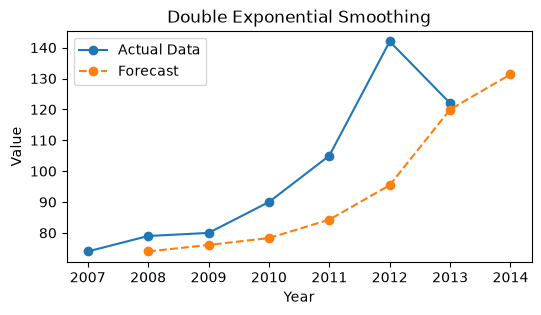

In [5]:
header = [c1, c2, "Level", "Trend", "Forecast"]

columns_to_round = [c2,'Level', 'Trend', 'Forecast']
data_set[columns_to_round] = data_set[columns_to_round].round(2)

plt.figure(figsize=(6, 3))
plt.title('Double Exponential Smoothing')
plt.xlabel(c1)
plt.ylabel('Value')

plt.plot(data_set[c1], data_set[c2], label='Actual Data', marker='o')
plt.plot(data_set[c1], data_set['Forecast'], label='Forecast', linestyle='--', marker='o')

print(f'Alpha :  {alpha}')
print(f'Beta :   {beta}')
print(tabulate(data_set.replace({np.nan: ""}), header, tablefmt="grid"))
plt.legend()
plt.show()